# Лабораторная работа № 1. Статистический анализ результатов измерений

**Моделирование · вариант 16**  
Якименко Владислав Игоревич · P3313  
Преподаватель: Авксентьева Елена Юрьевна

**Цель:** исследовать заданную числовую последовательность, оценить её моменты и
корреляционные свойства, подобрать распределение и сформировать новую последовательность.

Порядок: исходные данные → характеристики → автокорреляция и гистограмма →
метод моментов → генератор → сравнение.

Этот notebook выполняет расчёт в Python. Готовые результаты Excel не используются
для вычислений; книга читается только в заключительной сверке.

## Как запустить

1. Открыть `Lab1.ipynb` в VS Code с расширениями **Python** и **Jupyter** либо в JupyterLab.
2. Установить пакеты в выбранное Python-окружение: `python -m pip install -r requirements.txt`.
3. Выбрать это окружение как kernel и нажать **Run All / Выполнить всё**.

Рядом должны оставаться папка `materials/` с исходной таблицей вариантов и
расчётная книга. Для самого расчёта достаточно таблицы вариантов; если готового
Excel нет, последняя сверка пропускается. Выводы и графики уже сохранены в notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy.stats import chi2
from IPython.display import display, Markdown

pd.set_option("display.float_format", lambda value: f"{value:.6f}")
BLUE, GREEN, RED = "#245581", "#28714d", "#d34b2a"
plt.rcParams.update({"font.family": "DejaVu Serif", "font.size": 10,
                     "figure.figsize": (9, 3), "axes.spines.top": False,
                     "axes.spines.right": False})


def show_table(frame, index=True):
    # Markdown-таблицы читаются и в режиме безопасного просмотра VS Code.
    if frame.index.nlevels > 1:
        frame, index = frame.reset_index(), False
    display(Markdown(frame.to_markdown(index=index, floatfmt=".6f")))

## 1. Исходная последовательность

В исходном файле `!_УИР1_Варианты_с.xlsx`, на листе `1-50`, в Q1 указан вариант 16,
а Q2:Q301 содержат 300 значений. Номер варианта принят как в текущем отчёте.
Размеры выборок: первые $n=10,20,50,100,200,300$ значений **одного** ряда.

ЧП — числовая последовательность. Физический смысл чисел в задании не указан.

In [2]:
VARIANT = 16
SEED = 8141
SIZES = [10, 20, 50, 100, 200, 300]
LAGS = np.arange(1, 11)
T = {0.90: 1.643, 0.95: 1.960, 0.99: 2.576}  # Из теоретического материала.

candidates = [Path.cwd(), Path.cwd() / "Modeling" / "Lab1", Path.cwd() / "Lab1"]
LAB_DIR = next((folder for folder in candidates
                if (folder / "materials" / "!_УИР1_Варианты_с.xlsx").exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Запусти notebook из папки Lab1 или корня репозитория ITMO_labs.")

source_path = LAB_DIR / "materials" / "!_УИР1_Варианты_с.xlsx"
with_source = openpyxl.load_workbook(source_path, read_only=True, data_only=True)
sheet = with_source["1-50"]
column = VARIANT + 1  # A — подпись, B — вариант 1, ..., Q — вариант 16.
assert 1 <= VARIANT <= 50 and sheet.cell(1, column).value == VARIANT
x = np.array([row[0] for row in sheet.iter_rows(
    min_row=2, max_row=301, min_col=column, max_col=column, values_only=True)], dtype=float)
with_source.close()

N = len(x)
assert N == 300 and np.isfinite(x).all() and (x >= 0).all()
print(f"Вариант {VARIANT}: {N} значений; минимум {x.min():.6f}, максимум {x.max():.6f}.")
show_table(pd.DataFrame({"i": np.arange(1, 11), "X_i": x[:10]}), index=False)

Вариант 16: 300 значений; минимум 0.008820, максимум 280.937940.


|         i |       X_i |
|----------:|----------:|
|  1.000000 |  5.618172 |
|  2.000000 |  1.961323 |
|  3.000000 |  0.958966 |
|  4.000000 |  3.342269 |
|  5.000000 |  3.238546 |
|  6.000000 |  0.329954 |
|  7.000000 |  0.505939 |
|  8.000000 |  7.174057 |
|  9.000000 |  4.758814 |
| 10.000000 | 12.695186 |

## 2. Оценки числовых характеристик

Обозначения — как в теоретическом материале:

$$
\widetilde m_n=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad
\widetilde D_n=\frac{\sum_{i=1}^{n}(X_i-\widetilde m_n)^2}{n-1},
$$
$$
\widetilde\sigma_n=\sqrt{\widetilde D_n},\qquad
\nu_n=\frac{\widetilde\sigma_n}{\widetilde m_n}.
$$

Для дисперсии используется делитель $n-1$ (`ddof=1`): поправка устраняет её
систематическое занижение. Среднее и эта оценка дисперсии несмещённые;
корень из несмещённой дисперсии сам по себе не гарантирует несмещённость СКО.

Доверительный полуинтервал среднего:

$$\varepsilon_p=t_p\sqrt{\frac{\widetilde D_n}{n}},\qquad
I_p=(\widetilde m_n-\varepsilon_p;\,\widetilde m_n+\varepsilon_p).$$

Применяется нормальное приближение из методического материала, с
$t_{0.90}=1.643$, $t_{0.95}=1.960$, $t_{0.99}=2.576$.
При малой выборке и сильной асимметрии оно ориентировочное.

In [3]:
def sample_stats(values):
    n = len(values)
    mean = np.mean(values)
    variance = np.var(values, ddof=1)
    std = np.sqrt(variance)
    return pd.Series({
        "Мат. ожидание": mean,
        "ε (0,90)": T[0.90] * std / np.sqrt(n),
        "ε (0,95)": T[0.95] * std / np.sqrt(n),
        "ε (0,99)": T[0.99] * std / np.sqrt(n),
        "Дисперсия": variance,
        "СКО": std,
        "Коэффициент вариации": std / mean,
    })


stats_x = pd.DataFrame({n: sample_stats(x[:n]) for n in SIZES})
errors_x = stats_x.sub(stats_x[N], axis=0).abs().div(stats_x[N].abs(), axis=0) * 100


def form_table(values, errors):
    rows, names = [], []
    for name in values.index:
        sign = "±" if name.startswith("ε") else ""
        rows.append([f"{sign}{value:.4f}" for value in values.loc[name]])
        rows.append([f"{value:.1f}" for value in errors.loc[name]])
        names.extend([(name, "Значение"), (name, "%")])
    return pd.DataFrame(rows, columns=values.columns,
                        index=pd.MultiIndex.from_tuples(names, names=["Характеристика", "Строка"]))

display(Markdown("**Форма 1. Характеристики заданной ЧП.**"))
show_table(form_table(stats_x, errors_x))

**Форма 1. Характеристики заданной ЧП.**

| Характеристика       | Строка   | 10      | 20       | 50       | 100      | 200      | 300      |
|:---------------------|:---------|:--------|:---------|:---------|:---------|:---------|:---------|
| Мат. ожидание        | Значение | 4.0583  | 7.9090   | 7.1905   | 7.7709   | 6.8667   | 8.0208   |
| Мат. ожидание        | %        | 49.4    | 1.4      | 10.4     | 3.1      | 14.4     | 0.0      |
| ε (0,90)             | Значение | ±1.9665 | ±5.1030  | ±2.7034  | ±3.3882  | ±1.9695  | ±2.1431  |
| ε (0,90)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| ε (0,95)             | Значение | ±2.3460 | ±6.0876  | ±3.2250  | ±4.0420  | ±2.3495  | ±2.5566  |
| ε (0,95)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| ε (0,99)             | Значение | ±3.0833 | ±8.0008  | ±4.2385  | ±5.3123  | ±3.0879  | ±3.3601  |
| ε (0,99)             | %        | 8.2     | 138.1    | 26.1     | 58.1     | 8.1      | 0.0      |
| Дисперсия            | Значение | 14.3262 | 192.9336 | 135.3663 | 425.2796 | 287.3934 | 510.4309 |
| Дисперсия            | %        | 97.2    | 62.2     | 73.5     | 16.7     | 43.7     | 0.0      |
| СКО                  | Значение | 3.7850  | 13.8901  | 11.6347  | 20.6223  | 16.9527  | 22.5927  |
| СКО                  | %        | 83.2    | 38.5     | 48.5     | 8.7      | 25.0     | 0.0      |
| Коэффициент вариации | Значение | 0.9326  | 1.7562   | 1.6181   | 2.6538   | 2.4688   | 2.8168   |
| Коэффициент вариации | %        | 66.9    | 37.7     | 42.6     | 5.8      | 12.4     | 0.0      |

Проценты в форме 1 показывают отклонение от заданной ЧП при $n=300$:

$$\delta_n(A)=\frac{|A_n-A_{300}|}{|A_{300}|}\cdot100\%.$$

300 значений — эталон сравнения по заданию, а не известная генеральная совокупность.
В строках $\varepsilon$ указан **полуинтервал** со знаком $\pm$.

In [4]:
mean_x = float(stats_x.loc["Мат. ожидание", N])
var_x = float(stats_x.loc["Дисперсия", N])
std_x = np.sqrt(var_x)
cv_x = std_x / mean_x
eps95 = float(stats_x.loc["ε (0,95)", N])

print(f"Среднее: {mean_x:.6f}")
print(f"Несмещённая дисперсия: {var_x:.6f}")
print(f"СКО: {std_x:.6f}; коэффициент вариации: {cv_x:.6f}")
print(f"95%-й интервал среднего: ({mean_x-eps95:.6f}; {mean_x+eps95:.6f})")
print(f"Отклонение дисперсии при n=10 от n=300: {errors_x.loc['Дисперсия', 10]:.2f}%")

Среднее: 8.020778
Несмещённая дисперсия: 510.430941
СКО: 22.592719; коэффициент вариации: 2.816774
95%-й интервал среднего: (5.464172; 10.577385)
Отклонение дисперсии при n=10 от n=300: 97.19%


## 3. График значений и распределение частот

График сохраняет порядок наблюдений; на нём ищем тренд, периодичность и выбросы.
Гистограмма сохраняет частоты попадания в интервалы, но теряет порядок чисел.
Для данного ряда используются 15 равных интервалов. Правая граница последнего
интервала включается (`numpy.histogram`).

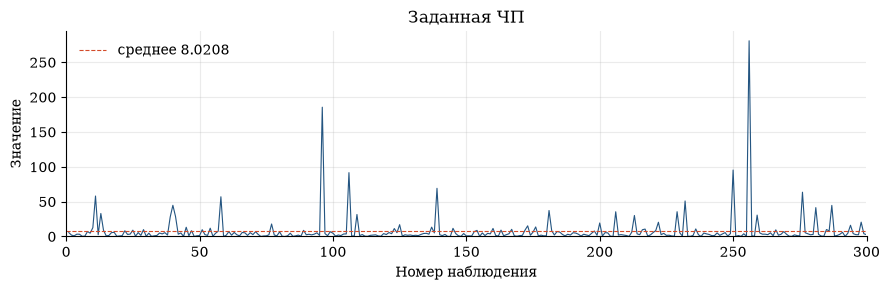

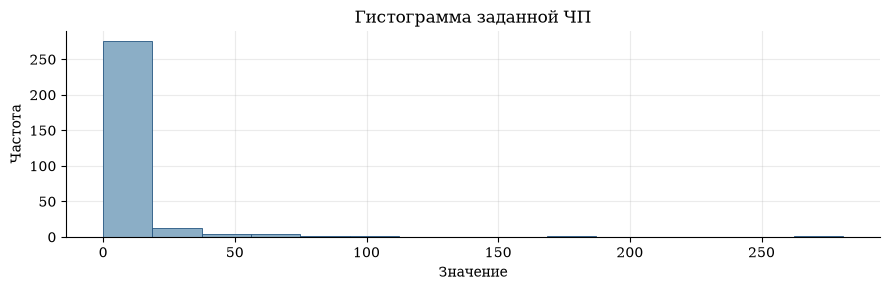

В первом интервале: 276 из 300 (92%).


In [5]:
fig, ax = plt.subplots()
ax.plot(np.arange(1, N + 1), x, color=BLUE, linewidth=0.8)
ax.axhline(mean_x, color=RED, linestyle="--", linewidth=0.8, label=f"среднее {mean_x:.4f}")
ax.set(xlabel="Номер наблюдения", ylabel="Значение", title="Заданная ЧП")
ax.set_xlim(0, N)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

source_edges = np.linspace(0, x.max(), 16)
source_counts, _ = np.histogram(x, bins=source_edges)
fig, ax = plt.subplots()
ax.hist(x, bins=source_edges, color="#8baec6", edgecolor=BLUE, linewidth=0.6)
ax.set(xlabel="Значение", ylabel="Частота", title="Гистограмма заданной ЧП")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
print(f"В первом интервале: {source_counts[0]} из {N} ({source_counts[0]/N:.0%}).")

Для варианта 16 преобладают малые значения с редкими крупными выбросами.
Выраженного устойчивого тренда на графике не видно; распределение асимметрично.
Визуальный анализ сам по себе не доказывает стационарность или независимость.

## 4. Автокорреляция

Для формы 3 вычисляется коэффициент Пирсона между рядом и его сдвинутой копией.
Для каждого лага $k$ средние двух подпоследовательностей считаются отдельно:

$$r_k=\frac{\sum_{i=1}^{N-k}(X_i-\widetilde m_{1,k})(X_{i+k}-\widetilde m_{2,k})}
{\sqrt{\sum_{i=1}^{N-k}(X_i-\widetilde m_{1,k})^2}
 \sqrt{\sum_{i=1}^{N-k}(X_{i+k}-\widetilde m_{2,k})^2}}.$$

При $k=1$ сравниваем соседние значения, при $k=2$ — значения через одну позицию.
Ориентировочные поточечные границы при 95%:

$$\pm\frac{1.96}{\sqrt N}.$$

95% — уровень доверия для границ. Его нельзя сравнивать непосредственно со
значением коэффициента корреляции.

|   k |       r_k | За границами   |
|----:|----------:|:---------------|
|   1 | -0.040973 | False          |
|   2 | -0.038591 | False          |
|   3 |  0.033551 | False          |
|   4 | -0.039807 | False          |
|   5 | -0.045090 | False          |
|   6 |  0.135367 | True           |
|   7 | -0.029357 | False          |
|   8 | -0.057194 | False          |
|   9 | -0.027037 | False          |
|  10 |  0.082232 | False          |

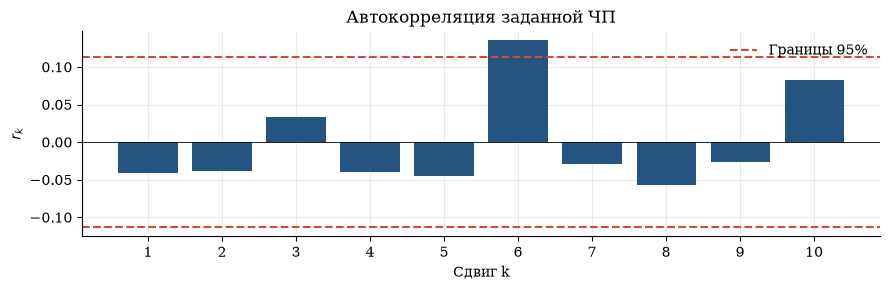

In [6]:
def pearson(left, right):
    a = np.asarray(left) - np.mean(left)
    b = np.asarray(right) - np.mean(right)
    return np.sum(a * b) / np.sqrt(np.sum(a**2) * np.sum(b**2))


def pairwise_acf(values, lags=LAGS):
    return np.array([pearson(values[:-k], values[k:]) for k in lags])


acf_x = pairwise_acf(x)
acf_limit = 1.96 / np.sqrt(N)
show_table(pd.DataFrame({"k": LAGS, "r_k": acf_x, "За границами": np.abs(acf_x) > acf_limit}), index=False)

fig, ax = plt.subplots()
ax.bar(LAGS, acf_x, width=0.8, color=BLUE)
ax.axhline(acf_limit, color=RED, linestyle="--", label="Границы 95%")
ax.axhline(-acf_limit, color=RED, linestyle="--")
ax.axhline(0, color="black", linewidth=0.6)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.set(xlabel="Сдвиг k", ylabel=r"$r_k$", xticks=LAGS, title="Автокорреляция заданной ЧП")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Совместная проверка десяти лагов

В дополнительном тесте Льюнга–Бокса нужна **стандартная АКФ с общим средним**,
а не попарные коэффициенты формы 3:

$$\widehat r_k=\frac{\sum_{i=1}^{N-k}(X_i-\widetilde m_N)(X_{i+k}-\widetilde m_N)}
{\sum_{i=1}^{N}(X_i-\widetilde m_N)^2},\qquad
Q=N(N+2)\sum_{k=1}^{10}\frac{\widehat r_k^2}{N-k}.$$

При гипотезе отсутствия серийной корреляции $Q$ приближённо сравнивается с
$\chi^2_{10}$. Параметры модели АКФ по данным не подбирались, поэтому здесь 10
степеней свободы. Один выход за поточечную границу при десяти проверках сам
по себе не доказывает периодичность.

In [7]:
def ljung_box(values, max_lag=10):
    centered = values - np.mean(values)
    denominator = np.sum(centered**2)
    lags = np.arange(1, max_lag + 1)
    acf = np.array([np.sum(centered[:-k] * centered[k:]) / denominator for k in lags])
    n = len(values)
    q = n * (n + 2) * np.sum(acf**2 / (n - lags))
    return q, chi2.sf(q, df=max_lag)


q_x, pvalue_x = ljung_box(x)
print(f"Льюнг–Бокс: Q = {q_x:.6f}; p-value = {pvalue_x:.6f}.")
print("Нулевая гипотеза при α=0,05: " +
      ("не отвергается." if pvalue_x > 0.05 else "отвергается."))

Льюнг–Бокс: Q = 11.645951; p-value = 0.309450.
Нулевая гипотеза при α=0,05: не отвергается.


Для текущих данных $r_6\approx0.1354$ немного выше границы $0.1132$, но
совместная проверка даёт $p\text{-value}\approx0.309>0.05$.
Значимая серийная корреляция совместным тестом не обнаружена; независимость
наблюдений этим не доказана. В дальнейшем используется приближение независимых наблюдений.

В форме 3 остаются попарные коэффициенты Пирсона. В $Q$ подставляются
коэффициенты с общим средним и общим знаменателем; эти две оценки АКФ различаются.

## 5. Определение вида распределения и метод моментов

**Именно здесь выбирается аппроксимирующее распределение.** Сначала рассматриваем
гистограмму и значение $\nu=2.8168$, затем сравниваем семейства из методички:

| Закон | Условие / причина выбора |
|---|---|
| Равномерный | Проверяем границы по двум моментам и попадание наблюдений в отрезок |
| Экспоненциальный | $\nu=1$ |
| Нормированный Эрланга | $\nu=\frac{1}{\sqrt{k}}\leq1$ |
| Гипоэкспоненциальный | $0<\nu\leq1$ |
| Гиперэкспоненциальный | $\nu>1$; подходит нашему варианту |

Для равномерного закона границы $a=\widehat\alpha_1-\sqrt{3D^*}$,
$b=\widehat\alpha_1+\sqrt{3D^*}$. Здесь также используются два начальных момента.
Гистограмма резко убывает и имеет длинный правый хвост, а не постоянную высоту.

При $\nu>1$ выбирается двухфазный гиперэкспоненциальный закон $H_2$.
В обозначениях учебника $q$ — вероятность первой фазы, $t_1,t_2$ — средние фаз:

$$f(x)=\frac{q}{t_1}e^{-x/t_1}+\frac{1-q}{t_2}e^{-x/t_2},\qquad x\geq0.$$

Для метода моментов берём **два эмпирических начальных момента**:

$$\widehat\alpha_1=\frac1N\sum X_i=\widetilde m,\qquad
\widehat\alpha_2=\frac1N\sum X_i^2
=\frac{N-1}{N}\widetilde D+\widetilde m^2.$$

При аппроксимации используем $D^*=\widehat\alpha_2-\widehat\alpha_1^2$ и
$\nu=\sqrt{D^*}/\widehat\alpha_1$. Эта дисперсия имеет делитель $N$.
В формах 1 и 2 по-прежнему рассчитывается **несмещённая** дисперсия с делителем $n-1$.

$$t=qt_1+(1-q)t_2=\widehat\alpha_1,\qquad
t^{(2)}=2\left[qt_1^2+(1-q)t_2^2\right]=\widehat\alpha_2.$$

Используем формулы (2.39)–(2.41) учебника, печатная с. 66:

$$t_1=t\left[1-\sqrt{\frac{1-q}{2q}(\nu^2-1)}\right],\qquad
t_2=t\left[1+\sqrt{\frac{q}{2(1-q)}(\nu^2-1)}\right],$$
$$q\geq\frac{\nu^2-1}{\nu^2+1}.$$

Два момента не определяют три параметра однозначно. В допустимом диапазоне
выбираем равные вклады фаз в среднее: $qt_1=(1-q)t_2=t/2$. Отсюда

$$q=\frac12\left(1+\sqrt{\frac{\nu^2-1}{\nu^2+1}}\right).$$

Это дополнительное условие выбора, а не обязательное требование учебника.
Материал: `materials/методичка/468.pdf`, разделы 2.3 и 2.6.2.

In [8]:
alpha1 = np.mean(x)
alpha2 = np.mean(x**2)
variance_moments = alpha2 - alpha1**2
a_uniform = alpha1 - np.sqrt(3 * variance_moments)
b_uniform = alpha1 + np.sqrt(3 * variance_moments)
outside_uniform = np.sum((x < a_uniform) | (x > b_uniform))
print(f"Равномерный закон: a={a_uniform:.4f}, b={b_uniform:.4f}; вне отрезка {outside_uniform} значений.")
print("Равномерная модель не включает все исходные значения." if outside_uniform else
      "Все значения входят в отрезок; равномерную модель нужно дополнительно оценить по гистограмме.")

if np.isclose(cv_x, 1.0, rtol=0, atol=1e-12):
    distribution_name = "Экспоненциальный"
elif cv_x > 1:
    distribution_name = "Гиперэкспоненциальный"
else:
    distribution_name = "Нормированный Эрланга или гипоэкспоненциальный"
print(f"По коэффициенту вариации ν={cv_x:.4f}: {distribution_name} закон.")
print("Это выбор моментной аппроксимации, а не доказательство точного закона исходных данных.")

if distribution_name != "Гиперэкспоненциальный":
    raise ValueError("Данная двухфазная гиперэкспоненциальная модель требует ν > 1.")

nu = np.sqrt(variance_moments) / alpha1
q = 0.5 * (1 + np.sqrt((nu**2 - 1) / (nu**2 + 1)))
q_min = (nu**2 - 1) / (nu**2 + 1)
t1 = alpha1 * (1 - np.sqrt((1-q) * (nu**2-1) / (2*q)))
t2 = alpha1 * (1 + np.sqrt(q * (nu**2-1) / (2*(1-q))))
assert q_min < q < 1 and t1 > 0 and t2 > 0

model_mean = q * t1 + (1 - q) * t2
model_second = 2 * (q * t1**2 + (1 - q) * t2**2)
model_var = model_second - model_mean**2
np.testing.assert_allclose([model_mean, model_second], [alpha1, alpha2], rtol=1e-12)
np.testing.assert_allclose(model_var, variance_moments, rtol=1e-12)

show_table(pd.Series({"α₁": alpha1, "α₂": alpha2, "D* (делитель N)": variance_moments,
                      "ν для аппроксимации": nu, "q (быстрая ветвь)": q,
                      "Нижняя граница q": q_min, "t₁": t1, "t₂": t2,
                      "M[X] модели": model_mean, "M[X²] модели": model_second,
                      "D[X] модели": model_var}).to_frame("Значение"))

Равномерный закон: a=-31.0457, b=47.0872; вне отрезка 9 значений.
Равномерная модель не включает все исходные значения.
По коэффициенту вариации ν=2.8168: Гиперэкспоненциальный закон.
Это выбор моментной аппроксимации, а не доказательство точного закона исходных данных.


|                     |   Значение |
|:--------------------|-----------:|
| α₁                  |   8.020778 |
| α₂                  | 573.062392 |
| D* (делитель N)     | 508.729505 |
| ν для аппроксимации |   2.812075 |
| q (быстрая ветвь)   |   0.940306 |
| Нижняя граница q    |   0.775477 |
| t₁                  |   4.264984 |
| t₂                  |  67.182245 |
| M[X] модели         |   8.020778 |
| M[X²] модели        | 573.062392 |
| D[X] модели         | 508.729505 |

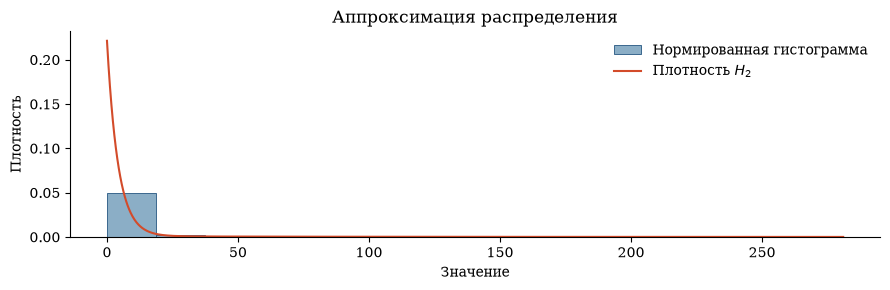

In [9]:
grid = np.linspace(0, x.max(), 1500)
density = q / t1 * np.exp(-grid/t1) + (1-q) / t2 * np.exp(-grid/t2)
fig, ax = plt.subplots()
ax.hist(x, bins=source_edges, density=True, color="#8baec6", edgecolor=BLUE,
        linewidth=0.6, label="Нормированная гистограмма")
ax.plot(grid, density, color=RED, label=r"Плотность $H_2$")
ax.set(xlabel="Значение", ylabel="Плотность", title="Аппроксимация распределения")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Плотность сравнивается с нормированной гистограммой
$\widehat f_j=\frac{n_j}{Nh}$, а не с необработанными частотами.
Совпадение двух моментов не означает совпадения частот каждого интервала и
не заменяет отдельную проверку гипотезы о распределении.

## 6. Генерация новой последовательности

Сначала формируем равномерные псевдослучайные числа тем же линейным конгруэнтным
генератором, что использован для сохранённых чисел Excel:

$$S_{k+1}=(1664525S_k+1013904223)\bmod 2^{32},\qquad S_0=8141,$$
$$U_{1,i}=\frac{S_{2i-1}+\frac12}{2^{32}},\qquad
U_{2,i}=\frac{S_{2i}+\frac12}{2^{32}}.$$

Сдвиг на $\frac12$ удерживает $U$ строго внутри $(0;1)$, чтобы логарифм был определён.
Первое число выбирает ветвь смеси, второе задаёт значение внутри этой ветви:

$$Y_i=\begin{cases}
-t_1\ln U_{2,i},&U_{1,i}\leq q,\\[2mm]
-t_2\ln U_{2,i},&U_{1,i}>q.
\end{cases}$$

Seed `8141` фиксирует одну воспроизводимую реализацию и не задан методичкой.
Его конкретное значение не имеет показанного здесь теоретического преимущества.
При другом seed новые 300 чисел и их выборочные характеристики изменятся.

In [10]:
def lcg_uniforms(seed, count):
    state = int(seed)
    modulus = 2**32
    values = np.empty(count)
    for i in range(count):
        state = (1664525 * state + 1013904223) % modulus
        values[i] = (state + 0.5) / modulus
    return values


uniforms = lcg_uniforms(SEED, 2 * N).reshape(N, 2)
u1, u2 = uniforms[:, 0], uniforms[:, 1]
fast_branch = u1 <= q
phase_means = np.where(fast_branch, t1, t2)
y = -np.log(u2) * phase_means

assert np.all((uniforms > 0) & (uniforms < 1))
assert np.isfinite(y).all() and (y >= 0).all()
show_table(pd.DataFrame({"i": np.arange(1, 11), "U₁": u1[:10], "U₂": u2[:10],
                        "Ветвь": np.where(fast_branch[:10], "быстрая", "медленная"),
                        "Y_i": y[:10]}), index=False)
print(f"Выборов быстрой ветви: {fast_branch.sum()} из {N}; медленной: {(~fast_branch).sum()}.")

|   i |       U₁ |       U₂ | Ветвь     |       Y_i |
|----:|---------:|---------:|:----------|----------:|
|   1 | 0.391132 | 0.697919 | быстрая   |  1.533910 |
|   2 | 0.029579 | 0.018102 | быстрая   | 17.110030 |
|   3 | 0.085882 | 0.735976 | быстрая   |  1.307461 |
|   4 | 0.416206 | 0.041298 | быстрая   | 13.592305 |
|   5 | 0.957679 | 0.269984 | медленная | 87.968049 |
|   6 | 0.577229 | 0.793440 | быстрая   |  0.986823 |
|   7 | 0.241166 | 0.632382 | быстрая   |  1.954479 |
|   8 | 0.814247 | 0.995971 | быстрая   |  0.017217 |
|   9 | 0.536175 | 0.057412 | быстрая   | 12.187235 |
|  10 | 0.158095 | 0.926584 | быстрая   |  0.325207 |

Выборов быстрой ветви: 283 из 300; медленной: 17.


## 7. Сравнение числовых характеристик

К новому ряду применяются те же функции расчёта. В форме 2 проценты относятся
к исходной последовательности **того же объёма**, а не ко всем 300 значениям:

$$\delta_n(A)=\frac{|A_n^{(Y)}-A_n^{(X)}|}{|A_n^{(X)}|}\cdot100\%.$$

In [11]:
stats_y = pd.DataFrame({n: sample_stats(y[:n]) for n in SIZES})
errors_y = (stats_y - stats_x).abs().div(stats_x.abs()) * 100
display(Markdown("**Форма 2. Характеристики сгенерированной ЧП.**"))
show_table(form_table(stats_y, errors_y))

comparison = pd.DataFrame({"Исходная ЧП": stats_x[N], "Сгенерированная ЧП": stats_y[N],
                           "Отклонение, %": errors_y[N]})
show_table(comparison)

**Форма 2. Характеристики сгенерированной ЧП.**

| Характеристика       | Строка   | 10       | 20        | 50       | 100      | 200      | 300      |
|:---------------------|:---------|:---------|:----------|:---------|:---------|:---------|:---------|
| Мат. ожидание        | Значение | 13.6983  | 18.0662   | 11.6051  | 9.7820   | 7.3307   | 8.0169   |
| Мат. ожидание        | %        | 237.5    | 128.4     | 61.4     | 25.9     | 6.8      | 0.0      |
| ε (0,90)             | Значение | ±13.9595 | ±14.5440  | ±6.1304  | ±3.9117  | ±2.0385  | ±2.1354  |
| ε (0,90)             | %        | 609.9    | 185.0     | 126.8    | 15.5     | 3.5      | 0.4      |
| ε (0,95)             | Значение | ±16.6529 | ±17.3501  | ±7.3132  | ±4.6665  | ±2.4318  | ±2.5474  |
| ε (0,95)             | %        | 609.9    | 185.0     | 126.8    | 15.5     | 3.5      | 0.4      |
| ε (0,99)             | Значение | ±21.8866 | ±22.8030  | ±9.6117  | ±6.1331  | ±3.1961  | ±3.3481  |
| ε (0,99)             | %        | 609.9    | 185.0     | 126.8    | 15.5     | 3.5      | 0.4      |
| Дисперсия            | Значение | 721.8829 | 1567.1920 | 696.1111 | 566.8433 | 307.8748 | 506.7800 |
| Дисперсия            | %        | 4938.9   | 712.3     | 414.2    | 33.3     | 7.1      | 0.7      |
| СКО                  | Значение | 26.8679  | 39.5878   | 26.3839  | 23.8085  | 17.5464  | 22.5118  |
| СКО                  | %        | 609.9    | 185.0     | 126.8    | 15.5     | 3.5      | 0.4      |
| Коэффициент вариации | Значение | 1.9614   | 2.1913    | 2.2735   | 2.4339   | 2.3936   | 2.8080   |
| Коэффициент вариации | %        | 110.3    | 24.8      | 40.5     | 8.3      | 3.0      | 0.3      |

|                      |   Исходная ЧП |   Сгенерированная ЧП |   Отклонение, % |
|:---------------------|--------------:|---------------------:|----------------:|
| Мат. ожидание        |      8.020778 |             8.016906 |        0.048281 |
| ε (0,90)             |      2.143115 |             2.135437 |        0.358274 |
| ε (0,95)             |      2.556607 |             2.547447 |        0.358274 |
| ε (0,99)             |      3.360112 |             3.348073 |        0.358274 |
| Дисперсия            |    510.430941 |           506.780013 |        0.715264 |
| СКО                  |     22.592719 |            22.511775 |        0.358274 |
| Коэффициент вариации |      2.816774 |             2.808038 |        0.310142 |

In [12]:
mean_error = float(errors_y.loc["Мат. ожидание", N])
variance_error = float(errors_y.loc["Дисперсия", N])
display(Markdown(
    f"При **n={N}**: среднее нового ряда **{y.mean():.6f}**, "
    f"дисперсия **{y.var(ddof=1):.6f}**. "
    f"Отклонения от заданного ряда: **{mean_error:.4f}%** и **{variance_error:.4f}%**. "
    "На малых выборках редкие большие значения могут сильно менять оценки. "
    "Близость моментов одной реализации не доказывает качество генератора."))

При **n=300**: среднее нового ряда **8.016906**, дисперсия **506.780013**. Отклонения от заданного ряда: **0.0483%** и **0.7153%**. На малых выборках редкие большие значения могут сильно менять оценки. Близость моментов одной реализации не доказывает качество генератора.

## 8. Сравнение графиков и частот

Для обеих гистограмм используются одинаковые 15 интервалов общего диапазона.
Это позволяет сравнивать частоты без смещения границ столбцов.

Как в образце, ряды показаны на двух панелях с одной шкалой. На сравнительной
гистограмме: заданная ЧП — заполненные столбцы, сгенерированная — контур,
теоретический закон — линия ожидаемых частот. Для последней используется

$$\widehat n_j=N\int_{a_{j-1}}^{a_j}f(x)\,dx
=N\left[q\left(e^{-a_{j-1}/t_1}-e^{-a_j/t_1}\right)
+(1-q)\left(e^{-a_{j-1}/t_2}-e^{-a_j/t_2}\right)\right].$$

Это перевод плотности в число наблюдений; сырую плотность с частотами напрямую
не смешиваем. График самой плотности в разделе 5 дан в нормированном масштабе.

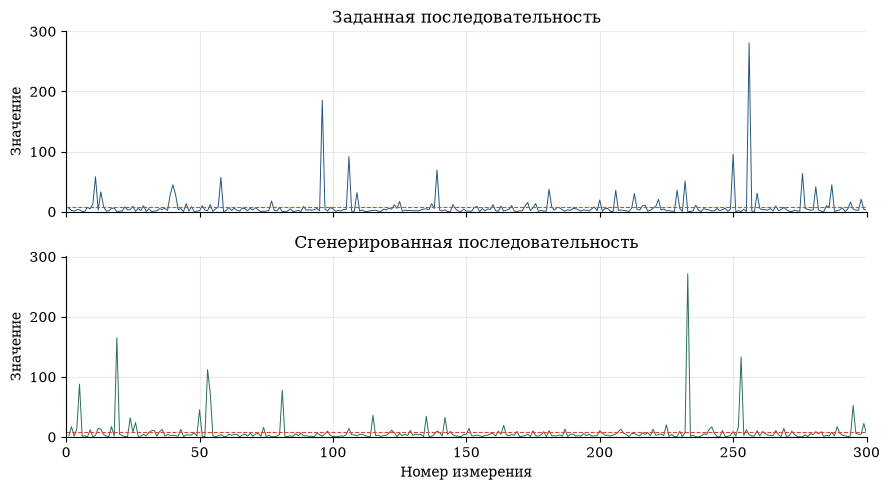

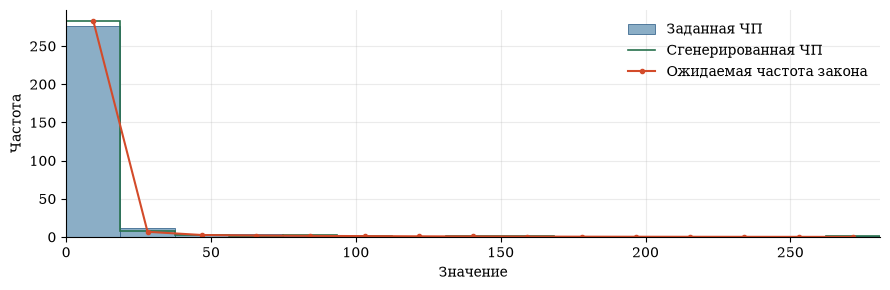

|   Левая граница |   Правая граница |   Частота X |   Частота Y |   Ожидаемая частота |
|----------------:|-----------------:|------------:|------------:|--------------------:|
|        0.000000 |        18.729196 |  276.000000 |  283.000000 |          282.955442 |
|       18.729196 |        37.458392 |   12.000000 |    8.000000 |            6.746991 |
|       37.458392 |        56.187588 |    4.000000 |    2.000000 |            2.537547 |
|       56.187588 |        74.916784 |    4.000000 |    1.000000 |            1.888374 |
|       74.916784 |        93.645980 |    1.000000 |    2.000000 |            1.428548 |
|       93.645980 |       112.375176 |    1.000000 |    1.000000 |            1.080984 |
|      112.375176 |       131.104372 |    0.000000 |    0.000000 |            0.817986 |
|      131.104372 |       149.833568 |    0.000000 |    1.000000 |            0.618974 |
|      149.833568 |       168.562764 |    0.000000 |    1.000000 |            0.468381 |
|      168.562764 |       187.291960 |    1.000000 |    0.000000 |            0.354426 |
|      187.291960 |       206.021156 |    0.000000 |    0.000000 |            0.268196 |
|      206.021156 |       224.750352 |    0.000000 |    0.000000 |            0.202945 |
|      224.750352 |       243.479548 |    0.000000 |    0.000000 |            0.153570 |
|      243.479548 |       262.208744 |    0.000000 |    0.000000 |            0.116207 |
|      262.208744 |       280.937940 |    1.000000 |    1.000000 |            0.087934 |

In [13]:
edges = np.linspace(0, max(x.max(), y.max()), 16)
counts_x, _ = np.histogram(x, bins=edges)
counts_y, _ = np.histogram(y, bins=edges)
assert counts_x.sum() == counts_y.sum() == N

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, sharey=True)
for ax, values, color, title in zip(axes, [x, y], [BLUE, GREEN],
    ["Заданная последовательность", "Сгенерированная последовательность"]):
    ax.plot(np.arange(1, N+1), values, color=color, linewidth=0.7)
    ax.axhline(values.mean(), color=RED, linestyle="--", linewidth=0.8)
    ax.set(title=title, ylabel="Значение", xlim=(0, N), ylim=(0, max(x.max(), y.max())*1.07))
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Номер измерения")
fig.tight_layout()
plt.show()

centers = (edges[:-1] + edges[1:]) / 2
expected_counts = N * (q * (np.exp(-edges[:-1]/t1)-np.exp(-edges[1:]/t1)) +
                       (1-q) * (np.exp(-edges[:-1]/t2)-np.exp(-edges[1:]/t2)))
fig, ax = plt.subplots()
ax.hist(x, bins=edges, color="#8baec6", edgecolor=BLUE, linewidth=0.5, label="Заданная ЧП")
ax.stairs(counts_y, edges, color=GREEN, linewidth=1.2, label="Сгенерированная ЧП")
ax.plot(centers, expected_counts, color=RED, marker=".", label="Ожидаемая частота закона")
ax.set(xlabel="Значение", ylabel="Частота", xlim=(0, edges[-1]))
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

show_table(pd.DataFrame({"Левая граница": edges[:-1], "Правая граница": edges[1:],
                        "Частота X": counts_x, "Частота Y": counts_y,
                        "Ожидаемая частота": expected_counts}), index=False)

## 9. Автокорреляция нового ряда и взаимная корреляция

Снова вычисляем попарные коэффициенты Пирсона. В форме 3 проценты:

$$\delta_k(r)=\frac{|r_k^{(Y)}-r_k^{(X)}|}{|r_k^{(X)}|}\cdot100\%.$$

Когда исходный коэффициент близок к нулю, такие проценты могут быть большими,
даже если оба коэффициента малы. Для вывода проверяем сами коэффициенты и границы.

**Форма 3. Коэффициенты автокорреляции.**

|                    |          1 |         2 |          3 |         4 |         5 |          6 |          7 |          8 |         9 |         10 |
|:-------------------|-----------:|----------:|-----------:|----------:|----------:|-----------:|-----------:|-----------:|----------:|-----------:|
| Исходная ЧП        |  -0.041000 | -0.039000 |   0.034000 | -0.040000 | -0.045000 |   0.135000 |  -0.029000 |  -0.057000 | -0.027000 |   0.082000 |
| Сгенерированная ЧП |   0.019000 | -0.032000 |  -0.008000 | -0.035000 | -0.018000 |  -0.016000 |   0.027000 |   0.015000 | -0.016000 |  -0.010000 |
| Отклонение, %      | 147.198000 | 16.151000 | 124.788000 | 12.830000 | 60.223000 | 112.110000 | 190.518000 | 125.671000 | 39.194000 | 111.646000 |

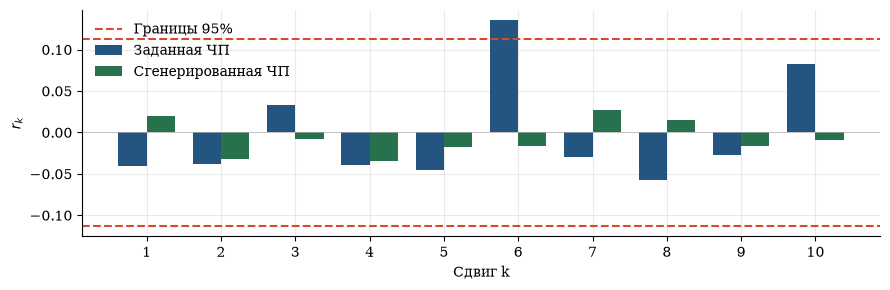

Максимум |r_k| нового ряда: 0.034700.
Поточечные границы 95%: ±0.113161.
Взаимная корреляция X и Y: -0.036074.
Льюнг–Бокс нового ряда (дополнительно): Q=1.366336; p-value=0.999295.


In [14]:
acf_y = pairwise_acf(y)
acf_errors = np.divide(np.abs(acf_y-acf_x), np.abs(acf_x),
                        out=np.full_like(acf_x, np.nan), where=np.abs(acf_x) > 0) * 100
form3 = pd.DataFrame([acf_x, acf_y, acf_errors], columns=LAGS,
                      index=["Исходная ЧП", "Сгенерированная ЧП", "Отклонение, %"])
form3.columns.name = "Лаг k"
display(Markdown("**Форма 3. Коэффициенты автокорреляции.**"))
show_table(form3.round(3))

fig, ax = plt.subplots()
ax.bar(LAGS-0.19, acf_x, width=0.38, color=BLUE, label="Заданная ЧП")
ax.bar(LAGS+0.19, acf_y, width=0.38, color=GREEN, label="Сгенерированная ЧП")
ax.axhline(acf_limit, color=RED, linestyle="--", label="Границы 95%")
ax.axhline(-acf_limit, color=RED, linestyle="--")
ax.axhline(0, color="0.7", linewidth=0.5)
ax.set(xlabel="Сдвиг k", ylabel=r"$r_k$", xticks=LAGS)
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

cross_correlation = pearson(x, y)
q_y, pvalue_y = ljung_box(y)
print(f"Максимум |r_k| нового ряда: {np.max(np.abs(acf_y)):.6f}.")
print(f"Поточечные границы 95%: ±{acf_limit:.6f}.")
print(f"Взаимная корреляция X и Y: {cross_correlation:.6f}.")
print(f"Льюнг–Бокс нового ряда (дополнительно): Q={q_y:.6f}; p-value={pvalue_y:.6f}.")

Взаимная корреляция относится к двум рядам без сдвига:

$$r_{XY}=\frac{\sum_{i=1}^N(X_i-\widetilde m_X)(Y_i-\widetilde m_Y)}
{\sqrt{\sum_{i=1}^N(X_i-\widetilde m_X)^2}\sqrt{\sum_{i=1}^N(Y_i-\widetilde m_Y)^2}}.$$

Малая линейная корреляция не доказывает независимость. При стандартном seed
все десять коэффициентов нового ряда находятся внутри указанных границ.

## 10. Все исходные и сгенерированные значения

В таблице доступны все 300 пар значений и равномерные числа генератора.
Раскрывающаяся таблица нужна для проверки конкретных наблюдений; графики и
сводные характеристики выше используют весь массив, а не только первые строки.

In [15]:
all_values = pd.DataFrame({"i": np.arange(1, N+1), "X_i": x,
                           "U₁": u1, "U₂": u2, "Y_i": y})
display(Markdown("<details><summary>Показать все 300 строк</summary>\n\n" +
                 all_values.to_markdown(index=False, floatfmt=".8f") + "\n\n</details>"))

<details><summary>Показать все 300 строк</summary>

|            i |          X_i |         U₁ |         U₂ |          Y_i |
|-------------:|-------------:|-----------:|-----------:|-------------:|
|   1.00000000 |   5.61817205 | 0.39113228 | 0.69791910 |   1.53391036 |
|   2.00000000 |   1.96132338 | 0.02957888 | 0.01810177 |  17.11003029 |
|   3.00000000 |   0.95896627 | 0.08588186 | 0.73597644 |   1.30746143 |
|   4.00000000 |   3.34226925 | 0.41620571 | 0.04129750 |  13.59230475 |
|   5.00000000 |   3.23854620 | 0.95767924 | 0.26998353 |  87.96804861 |
|   6.00000000 |   0.32995368 | 0.57722867 | 0.79343957 |   0.98682301 |
|   7.00000000 |   0.50593862 | 0.24116574 | 0.63238196 |   1.95447882 |
|   8.00000000 |   7.17405661 | 0.81424656 | 0.99597140 |   0.01721660 |
|   9.00000000 |   4.75881447 | 0.53617508 | 0.05741153 |  12.18723508 |
|  10.00000000 |  12.69518606 | 0.15809477 | 0.92658412 |   0.32520693 |
|  11.00000000 |  58.10667878 | 0.66399561 | 0.53126900 |   2.69754606 |
|  12.00000000 |   2.58778952 | 0.76465826 | 0.03353540 |  14.48027604 |
|  13.00000000 |  33.03094563 | 0.74726532 | 0.04949332 |  12.82019022 |
|  14.00000000 |   8.89468535 | 0.10462993 | 0.37125740 |   4.22600050 |
|  15.00000000 |   0.98670570 | 0.46662467 | 0.67220245 |   1.69403335 |
|  16.00000000 |   1.41822019 | 0.02533914 | 0.87287873 |   0.57986146 |
|  17.00000000 |   5.60874963 | 0.69725224 | 0.01780675 |  17.18011375 |
|  18.00000000 |   5.89967161 | 0.01277571 | 0.72528544 |   1.36987018 |
|  19.00000000 |   0.32563964 | 0.97840816 | 0.08582388 | 164.96317805 |
|  20.00000000 |   0.73708237 | 0.23193411 | 0.36234618 |   4.32962071 |
|  21.00000000 |   1.19277850 | 0.51911045 | 0.54942037 |   2.55426236 |
|  22.00000000 |   8.22489277 | 0.17360304 | 0.84192635 |   0.73384482 |
|  23.00000000 |   2.98079740 | 0.69306900 | 0.90830462 |   0.41018684 |
|  24.00000000 |   3.43565555 | 0.98572529 | 0.62231627 |  31.86499824 |
|  25.00000000 |   9.09352390 | 0.22600256 | 0.14259659 |   8.30706160 |
|  26.00000000 |   0.40281571 | 0.81745289 | 0.00369853 |  23.88314394 |
|  27.00000000 |   5.62372732 | 0.52846339 | 0.75829893 |   1.18002557 |
|  28.00000000 |   1.60824978 | 0.75402263 | 0.75027929 |   1.22537148 |
|  29.00000000 |   9.91962366 | 0.87729480 | 0.36499478 |   4.29855890 |
|  30.00000000 |   0.26659133 | 0.17057684 | 0.65870874 |   1.78051914 |
|  31.00000000 |   4.80700386 | 0.39884648 | 0.17639708 |   7.39982266 |
|  32.00000000 |   0.10920043 | 0.58305454 | 0.08841551 |  10.34560535 |
|  33.00000000 |   0.95280394 | 0.05707264 | 0.07437442 |  11.08317140 |
|  34.00000000 |   1.45576112 | 0.32427779 | 0.71948025 |   1.40414447 |
|  35.00000000 |   4.99567238 | 0.09963797 | 0.12707853 |   8.79844889 |
|  36.00000000 |   3.70770686 | 0.62335851 | 0.05367323 |  12.47439978 |
|  37.00000000 |   5.53866041 | 0.66515641 | 0.70179822 |   1.51027072 |
|  38.00000000 |   2.06825573 | 0.91655048 | 0.42428096 |   3.65662408 |
|  39.00000000 |  28.04754299 | 0.50468772 | 0.56316501 |   2.44887963 |
|  40.00000000 |  44.79204767 | 0.46767173 | 0.53034697 |   2.70495448 |
|  41.00000000 |  28.59260698 | 0.02061691 | 0.59733521 |   2.19764743 |
|  42.00000000 |   3.31218010 | 0.62622221 | 0.76095153 |   1.16513229 |
|  43.00000000 |   5.09352942 | 0.07604140 | 0.05277365 |  12.54648759 |
|  44.00000000 |   0.09855883 | 0.30132175 | 0.82515555 |   0.81965897 |
|  45.00000000 |  13.25402738 | 0.27779108 | 0.43826392 |   3.51833030 |
|  46.00000000 |   1.04454967 | 0.47959341 | 0.45323348 |   3.37508606 |
|  47.00000000 |   8.32090686 | 0.68620611 | 0.46877015 |   3.23133406 |
|  48.00000000 |   0.07655887 | 0.86511704 | 0.18482025 |   7.20087769 |
|  49.00000000 |   1.00827782 | 0.15479759 | 0.69977545 |   1.52258127 |
|  50.00000000 |   1.31976315 | 0.96957827 | 0.50959734 |  45.28986137 |
|  51.00000000 |   9.76667129 | 0.75291600 | 0.74072182 |   1.28005019 |
|  52.00000000 |   2.74576461 | 0.23073768 | 0.87614289 |   0.56394215 |
|  53.00000000 |   1.56828700 | 0.97455247 | 0.18817666 | 112.21948042 |
|  54.00000000 |  11.89018192 | 0.98734540 | 0.33457079 |  73.55829511 |
|  55.00000000 |   0.34504206 | 0.68639788 | 0.66935081 |   1.71216494 |
|  56.00000000 |   4.65001582 | 0.38862594 | 0.82858400 |   0.80197504 |
|  57.00000000 |   7.64724793 | 0.01828474 | 0.63659322 |   1.92617088 |
|  58.00000000 |  57.03848140 | 0.56645840 | 0.40256675 |   3.88068489 |
|  59.00000000 |   0.09392040 | 0.64913688 | 0.80348713 |   0.93315339 |
|  60.00000000 |   1.82704825 | 0.64837693 | 0.83934093 |   0.74696207 |
|  61.00000000 |   7.10520939 | 0.19155202 | 0.36317280 |   4.31990215 |
|  62.00000000 |   1.88326273 | 0.43951653 | 0.49421150 |   3.00592539 |
|  63.00000000 |   5.81843324 | 0.62814205 | 0.37952186 |   4.13210027 |
|  64.00000000 |   2.45078186 | 0.85162921 | 0.34092595 |   4.58950652 |
|  65.00000000 |   0.93811472 | 0.00275620 | 0.99178815 |   0.03516800 |
|  66.00000000 |   5.82197518 | 0.40729533 | 0.49517285 |   2.99763712 |
|  67.00000000 |   5.23958173 | 0.81971198 | 0.32336021 |   4.81511726 |
|  68.00000000 |   1.57232610 | 0.39745543 | 0.73124442 |   1.33497202 |
|  69.00000000 |   5.49667283 | 0.85415899 | 0.23524025 |   6.17206271 |
|  70.00000000 |   2.73606847 | 0.52038721 | 0.75748823 |   1.18458771 |
|  71.00000000 |   6.88317798 | 0.32670046 | 0.31487472 |   4.92853201 |
|  72.00000000 |   2.84266857 | 0.08025294 | 0.26617288 |   5.64517229 |
|  73.00000000 |   0.05714911 | 0.64539764 | 0.74096144 |   1.27867075 |
|  74.00000000 |   0.74938661 | 0.07334212 | 0.02339282 |  16.01640593 |
|  75.00000000 |   0.91633586 | 0.16828205 | 0.91485830 |   0.37952426 |
|  76.00000000 |   2.43392002 | 0.74013444 | 0.51463718 |   2.83319955 |
|  77.00000000 |  17.94931520 | 0.68950047 | 0.99921850 |   0.00333438 |
|  78.00000000 |   2.12172006 | 0.41130814 | 0.91164769 |   0.39451815 |
|  79.00000000 |   1.05626952 | 0.60221776 | 0.75447740 |   1.20157376 |
|  80.00000000 |   6.64472573 | 0.72581856 | 0.37619063 |   4.16970113 |
|  81.00000000 |   0.31471403 | 0.94140255 | 0.31381584 |  77.86079227 |
|  82.00000000 |   0.00882026 | 0.54917212 | 0.96636790 |   0.14590797 |
|  83.00000000 |   1.01304551 | 0.75962064 | 0.78722514 |   1.02035899 |
|  84.00000000 |   4.74177413 | 0.17002053 | 0.66109209 |   1.76511538 |
|  85.00000000 |   0.24387023 | 0.53896132 | 0.83529858 |   0.76755227 |
|  86.00000000 |   0.90299487 | 0.60320033 | 0.26835064 |   5.61041913 |
|  87.00000000 |   2.02046407 | 0.59222143 | 0.60337444 |   2.15474373 |
|  88.00000000 |   0.44828656 | 0.07734278 | 0.23288411 |   6.21499579 |
|  89.00000000 |   8.84209099 | 0.65647222 | 0.65665568 |   1.79383295 |
|  90.00000000 |   2.48690372 | 0.03517903 | 0.60890338 |   2.11584012 |
|  91.00000000 |   3.20380190 | 0.13213413 | 0.80693110 |   0.91491153 |
|  92.00000000 |   2.34372078 | 0.22466558 | 0.71347107 |   1.43991569 |
|  93.00000000 |   3.36788219 | 0.67068427 | 0.97152309 |   0.12321642 |
|  94.00000000 |   5.31664005 | 0.70905513 | 0.22617193 |   6.33972733 |
|  95.00000000 |   1.47453704 | 0.06412173 | 0.45508697 |   3.35768001 |
|  96.00000000 | 185.60540491 | 0.87403765 | 0.75069729 |   1.22299604 |
|  97.00000000 |   4.22074364 | 0.63931576 | 0.29488684 |   5.20824307 |
|  98.00000000 |   1.15199384 | 0.76007682 | 0.10396862 |   9.65449969 |
|  99.00000000 |   6.89053278 | 0.61036171 | 0.56017306 |   2.47159876 |
| 100.00000000 |   4.68115172 | 0.29806678 | 0.84842514 |   0.70105002 |
| 101.00000000 |   0.59820421 | 0.09206982 | 0.74628620 |   1.24813094 |
| 102.00000000 |   2.16152737 | 0.27643418 | 0.83310043 |   0.77879068 |
| 103.00000000 |   1.33055800 | 0.72771176 | 0.65411266 |   1.81038194 |
| 104.00000000 |   3.58838282 | 0.11781050 | 0.75911320 |   1.17544822 |
| 105.00000000 |   3.72013047 | 0.13415008 | 0.39551677 |   3.95603741 |
| 106.00000000 |  91.66518222 | 0.79339980 | 0.03519706 |  14.27401765 |
| 107.00000000 |   0.88184010 | 0.61747536 | 0.41537449 |   3.74710739 |
| 108.00000000 |   0.69908127 | 0.45316664 | 0.43889436 |   3.51219956 |
| 109.00000000 |  31.60759791 | 0.86227629 | 0.67083364 |   1.70272704 |
| 110.00000000 |   1.32365720 | 0.59996943 | 0.34903910 |   4.48919981 |
| 111.00000000 |   2.77502621 | 0.54766743 | 0.35842577 |   4.37601731 |
| 112.00000000 |   0.48904754 | 0.88576400 | 0.56515394 |   2.43384351 |
| 113.00000000 |   0.24516435 | 0.09319992 | 0.82965448 |   0.79646850 |
| 114.00000000 |   1.65433640 | 0.85800258 | 0.97938616 |   0.08883650 |
| 115.00000000 |   1.95550388 | 0.98777991 | 0.58568540 |  35.94065233 |
| 116.00000000 |   2.39089563 | 0.23435297 | 0.61660784 |   2.06221377 |
| 117.00000000 |   0.81545813 | 0.40471982 | 0.49176269 |   3.02711079 |
| 118.00000000 |   0.41063414 | 0.53386316 | 0.80830496 |   0.90765624 |
| 119.00000000 |   4.20266892 | 0.05604744 | 0.60197708 |   2.16463248 |
| 120.00000000 |   2.82509377 | 0.14269613 | 0.51588066 |   2.82290683 |
| 121.00000000 |   5.66400548 | 0.48919782 | 0.23501053 |   6.17622968 |
| 122.00000000 |   4.02993239 | 0.14256009 | 0.06899749 |  11.40322445 |
| 123.00000000 |  11.39265420 | 0.27921296 | 0.19148240 |   7.04984523 |
| 124.00000000 |   5.48812603 | 0.47995891 | 0.83458379 |   0.77120350 |
| 125.00000000 |  16.99687900 | 0.81957436 | 0.25352222 |   5.85285378 |
| 126.00000000 |   0.54884665 | 0.30438795 | 0.58212909 |   2.30762522 |
| 127.00000000 |   2.48242001 | 0.66479333 | 0.35719398 |   4.39069979 |
| 128.00000000 |   1.74935213 | 0.55360017 | 0.56089358 |   2.46611644 |
| 129.00000000 |   2.18054319 | 0.62788414 | 0.07839707 |  10.85851595 |
| 130.00000000 |   1.33626964 | 0.11406757 | 0.55465664 |   2.51380721 |
| 131.00000000 |   1.75755257 | 0.08584496 | 0.32286863 |   4.82160605 |
| 132.00000000 |   1.25749163 | 0.13476289 | 0.42962945 |   3.60319573 |
| 133.00000000 |   2.98278502 | 0.19627168 | 0.36091262 |   4.34652785 |
| 134.00000000 |   4.32778033 | 0.32238669 | 0.94115663 |   0.25865294 |
| 135.00000000 |   4.56558348 | 0.97822944 | 0.59748040 |  34.60112680 |
| 136.00000000 |   3.34643165 | 0.29616472 | 0.81483199 |   0.87335497 |
| 137.00000000 |  13.45963471 | 0.46050704 | 0.71822778 |   1.41157543 |
| 138.00000000 |   5.16042807 | 0.33034057 | 0.36765330 |   4.26760649 |
| 139.00000000 |  69.15622636 | 0.35037916 | 0.10217379 |   9.72877005 |
| 140.00000000 |   2.55294283 | 0.06248867 | 0.18484113 |   7.20039566 |
| 141.00000000 |   1.26837783 | 0.92600136 | 0.64158589 |   1.89285195 |
| 142.00000000 |   3.00998713 | 0.99577260 | 0.61794678 |  32.33837066 |
| 143.00000000 |   0.10661434 | 0.10556292 | 0.35971682 |   4.36068241 |
| 144.00000000 |   0.12226544 | 0.87327369 | 0.11987423 |   9.04736223 |
| 145.00000000 |  11.74398795 | 0.89632251 | 0.46701793 |   3.24730605 |
| 146.00000000 |   4.30891647 | 0.25251495 | 0.68244120 |   1.62956041 |
| 147.00000000 |   1.08861211 | 0.67665160 | 0.74645417 |   1.24717114 |
| 148.00000000 |   0.22838052 | 0.85830532 | 0.89210422 |   0.48694309 |
| 149.00000000 |   4.24293056 | 0.01421076 | 0.40854556 |   3.81780820 |
| 150.00000000 |   0.83967695 | 0.54202919 | 0.36947282 |   4.24655119 |
| 151.00000000 |   0.97172959 | 0.97338374 | 0.80676030 |  14.42595468 |
| 152.00000000 |   0.72857177 | 0.92550630 | 0.60823771 |   2.12050524 |
| 153.00000000 |   7.10171743 | 0.11509435 | 0.65388433 |   1.81187097 |
| 154.00000000 |   8.76755564 | 0.05754689 | 0.47913814 |   3.13803164 |
| 155.00000000 |   0.13799158 | 0.64213118 | 0.62999260 |   1.97062395 |
| 156.00000000 |   5.13494139 | 0.66132721 | 0.91459315 |   0.38076054 |
| 157.00000000 |   1.32066137 | 0.39310511 | 0.52264674 |   2.76733268 |
| 158.00000000 |   4.48641335 | 0.80071029 | 0.53962206 |   2.63101010 |
| 159.00000000 |   3.77757647 | 0.63816467 | 0.28994446 |   5.28033113 |
| 160.00000000 |  11.58202365 | 0.04363709 | 0.26467890 |   5.66917830 |
| 161.00000000 |   1.53407409 | 0.87959415 | 0.68704538 |   1.60088276 |
| 162.00000000 |   0.58250576 | 0.45071289 | 0.10602597 |   9.57092783 |
| 163.00000000 |   9.18445574 | 0.11041956 | 0.34679847 |   4.51666678 |
| 164.00000000 |   1.01659172 | 0.96711405 | 0.74927141 |  19.39242323 |
| 165.00000000 |   2.61322584 | 0.23414741 | 0.45509608 |   3.35759459 |
| 166.00000000 |   3.97835525 | 0.04594006 | 0.62169590 |   2.02716487 |
| 167.00000000 |  10.30182863 | 0.59876131 | 0.41157949 |   3.78625280 |
| 168.00000000 |   0.88498496 | 0.58113591 | 0.48899332 |   3.05119701 |
| 169.00000000 |   0.38734717 | 0.84810134 | 0.11632102 |   9.17569297 |
| 170.00000000 |   1.28477517 | 0.47810973 | 0.84205062 |   0.73321535 |
| 171.00000000 |   1.61561302 | 0.54375124 | 0.77310777 |   1.09753744 |
| 172.00000000 |   9.20096223 | 0.44017083 | 0.58939158 |   2.25474557 |
| 173.00000000 |  15.33933078 | 0.26055849 | 0.34995183 |   4.47806160 |
| 174.00000000 |   1.75789470 | 0.79891295 | 0.82090979 |   0.84166068 |
| 175.00000000 |   6.24033442 | 0.10891206 | 0.08745211 |  10.39233246 |
| 176.00000000 |  13.74135199 | 0.46666792 | 0.65851558 |   1.78176996 |
| 177.00000000 |   0.73169810 | 0.88690315 | 0.69563275 |   1.54790520 |
| 178.00000000 |   1.96879473 | 0.33915455 | 0.45932208 |   3.31817298 |
| 179.00000000 |   0.99862745 | 0.31549355 | 0.12988299 |   8.70534954 |
| 180.00000000 |   0.95548179 | 0.72644788 | 0.88699528 |   0.51143817 |
| 181.00000000 |  37.32623879 | 0.05981698 | 0.08662375 |  10.43292361 |
| 182.00000000 |   8.34631235 | 0.64039373 | 0.61689326 |   2.06024003 |
| 183.00000000 |   2.15495572 | 0.48973814 | 0.60932565 |   2.11288339 |
| 184.00000000 |   7.07564549 | 0.01659360 | 0.69061933 |   1.57875418 |
| 185.00000000 |   6.37945604 | 0.38279462 | 0.44550365 |   3.44845210 |
| 186.00000000 |   3.05312186 | 0.19908475 | 0.78561439 |   1.02909461 |
| 187.00000000 |   0.86095104 | 0.02264659 | 0.04531325 |  13.19652528 |
| 188.00000000 |   3.22969157 | 0.26584081 | 0.91541320 |   0.37693813 |
| 189.00000000 |   2.09127881 | 0.39615933 | 0.34237322 |   4.57143946 |
| 190.00000000 |   5.42629542 | 0.02321749 | 0.32618988 |   4.77795756 |
| 191.00000000 |   4.93382126 | 0.44224357 | 0.70743997 |   1.47612163 |
| 192.00000000 |   3.28917902 | 0.74746872 | 0.60521730 |   2.14173727 |
| 193.00000000 |   0.58370147 | 0.55557861 | 0.71555835 |   1.42745657 |
| 194.00000000 |   3.31410416 | 0.00145809 | 0.26686566 |   5.63408602 |
| 195.00000000 |   2.14069807 | 0.79834330 | 0.61731417 |   2.05733100 |
| 196.00000000 |   1.23436836 | 0.10469058 | 0.33176509 |   4.70567674 |
| 197.00000000 |   4.74219906 | 0.52307981 | 0.65481314 |   1.80581707 |
| 198.00000000 |   7.86229118 | 0.08478961 | 0.66475729 |   1.74153492 |
| 199.00000000 |   1.73454090 | 0.35981519 | 0.61301149 |   2.08716202 |
| 200.00000000 |  19.40781994 | 0.18854439 | 0.08726125 |  10.40165090 |
| 201.00000000 |   0.66004619 | 0.77056578 | 0.24702305 |   5.96361458 |
| 202.00000000 |   5.51490906 | 0.28065261 | 0.52967807 |   2.71033706 |
| 203.00000000 |   5.22871972 | 0.62434943 | 0.47602798 |   3.16580653 |
| 204.00000000 |   0.45966709 | 0.70828345 | 0.73945976 |   1.28732319 |
| 205.00000000 |   0.10258411 | 0.49583049 | 0.48440800 |   3.09137876 |
| 206.00000000 |  35.51361945 | 0.45958581 | 0.31046719 |   4.98865383 |
| 207.00000000 |   2.05680451 | 0.64072266 | 0.12073322 |   9.01690962 |
| 208.00000000 |   2.69939119 | 0.69426702 | 0.04924205 |  12.84189848 |
| 209.00000000 |   2.01398383 | 0.85107463 | 0.23522551 |   6.17233008 |
| 210.00000000 |   1.39884287 | 0.97436669 | 0.94381785 |   3.88461755 |
| 211.00000000 |   0.13872244 | 0.64356355 | 0.84632345 |   0.71162821 |
| 212.00000000 |   6.11036141 | 0.77335096 | 0.25069509 |   5.90068145 |
| 213.00000000 |  30.18302734 | 0.48392126 | 0.27697382 |   5.47552406 |
| 214.00000000 |   3.76840565 | 0.09165211 | 0.46560536 |   3.26022568 |
| 215.00000000 |   2.59551015 | 0.00061844 | 0.65127470 |   1.82892646 |
| 216.00000000 |   9.71787789 | 0.25677833 | 0.19368958 |   7.00096471 |
| 217.00000000 |  10.65561991 | 0.39093144 | 0.39209504 |   3.99309556 |
| 218.00000000 |   0.66176037 | 0.23611898 | 0.18471530 |   7.20330011 |
| 219.00000000 |   2.27270540 | 0.47251701 | 0.61029591 |   2.10609743 |
| 220.00000000 |   5.55332072 | 0.04057002 | 0.04895802 |  12.86656989 |
| 221.00000000 |   8.46842711 | 0.08361983 | 0.52617823 |   2.73861142 |
| 222.00000000 |  20.45707395 | 0.04710484 | 0.41937162 |   3.70626180 |
| 223.00000000 |   2.70737937 | 0.78503782 | 0.31378206 |   4.94335787 |
| 224.00000000 |   4.47072785 | 0.31841537 | 0.57567284 |   2.35519140 |
| 225.00000000 |   1.61692378 | 0.06697032 | 0.00866254 |  20.25333184 |
| 226.00000000 |   1.85864949 | 0.24774849 | 0.79596478 |   0.97327078 |
| 227.00000000 |   0.75946523 | 0.51387401 | 0.36976727 |   4.24315348 |
| 228.00000000 |   0.53514918 | 0.10706281 | 0.95152455 |   0.21192618 |
| 229.00000000 |  35.59966136 | 0.63045169 | 0.83604037 |   0.76376643 |
| 230.00000000 |   5.32373597 | 0.32663065 | 0.11037987 |   9.39928912 |
| 231.00000000 |   0.56462223 | 0.28189888 | 0.96837797 |   0.13704587 |
| 232.00000000 |  51.00832745 | 0.58421047 | 0.16529984 |   7.67694659 |
| 233.00000000 |   0.33250052 | 0.95153319 | 0.01756044 | 271.55778562 |
| 234.00000000 |   0.27953683 | 0.03191452 | 0.75182471 |   1.21659552 |
| 235.00000000 |   1.57151788 | 0.26893154 | 0.50878599 |   2.88196823 |
| 236.00000000 |  10.88798840 | 0.23889682 | 0.97195973 |   0.12129999 |
| 237.00000000 |   2.55054569 | 0.51170018 | 0.98343097 |   0.07125862 |
| 238.00000000 |   0.11313519 | 0.67798648 | 0.68915805 |   1.58778806 |
| 239.00000000 |   4.93968333 | 0.03400252 | 0.28866169 |   5.29924216 |
| 240.00000000 |   3.80620203 | 0.83439130 | 0.41021768 |   3.80038786 |
| 241.00000000 |   2.94497888 | 0.82496978 | 0.05552276 |  12.32990735 |
| 242.00000000 |   1.24356887 | 0.26459668 | 0.01971759 |  16.74536929 |
| 243.00000000 |   1.26926208 | 0.65011942 | 0.25612709 |   5.80925578 |
| 244.00000000 |   5.15319474 | 0.18358489 | 0.88261771 |   0.53253919 |
| 245.00000000 |   1.59796894 | 0.47890644 | 0.98057234 |   0.08367412 |
| 246.00000000 |   3.69070086 | 0.40849963 | 0.08064818 |  10.73777533 |
| 247.00000000 |   5.59825062 | 0.15153247 | 0.82420901 |   0.82455417 |
| 248.00000000 |   0.66090317 | 0.73688083 | 0.79811253 |   0.96177812 |
| 249.00000000 |   4.16182723 | 0.48813763 | 0.52588507 |   2.74098826 |
| 250.00000000 |  95.41370538 | 0.08759489 | 0.12272994 |   8.94695084 |
| 251.00000000 |   0.20017134 | 0.29350025 | 0.74779216 |   1.23953314 |
| 252.00000000 |   1.40636490 | 0.98258515 | 0.77714166 |  16.93883576 |
| 253.00000000 |   0.18234555 | 0.96036942 | 0.13753831 | 133.27968091 |
| 254.00000000 |   3.93986502 | 0.19756766 | 0.54670635 |   2.57538266 |
| 255.00000000 |   0.47409309 | 0.62455525 | 0.06307230 |  11.78617041 |
| 256.00000000 | 280.93793988 | 0.65979735 | 0.41920959 |   3.70790999 |
| 257.00000000 |   1.18113539 | 0.07490210 | 0.66108450 |   1.76516428 |
| 258.00000000 |   0.30250723 | 0.92102940 | 0.70211240 |   1.50836182 |
| 259.00000000 |  30.72642562 | 0.87126949 | 0.08950935 |  10.29316438 |
| 260.00000000 |   5.06339582 | 0.78380102 | 0.63296384 |   1.95055622 |
| 261.00000000 |   3.31053181 | 0.37364587 | 0.12475431 |   8.87717589 |
| 262.00000000 |   3.34448854 | 0.90915848 | 0.24860269 |   5.93642804 |
| 263.00000000 |   2.64289163 | 0.63552020 | 0.49428050 |   3.00532995 |
| 264.00000000 |   5.27638387 | 0.48395446 | 0.52877315 |   2.71762973 |
| 265.00000000 |   1.18041803 | 0.36463637 | 0.58515975 |   2.28547860 |
| 266.00000000 |   9.56459568 | 0.27584076 | 0.07977962 |  10.78395747 |
| 267.00000000 |   1.84439124 | 0.40425538 | 0.41923337 |   3.70766809 |
| 268.00000000 |   3.25497704 | 0.65408128 | 0.87380556 |   0.57533524 |
| 269.00000000 |   7.08865555 | 0.43805037 | 0.03549732 |  14.23778837 |
| 270.00000000 |   3.27719490 | 0.40431028 | 0.80952142 |   0.90124250 |
| 271.00000000 |   0.46462248 | 0.87175947 | 0.67033909 |   1.70587240 |
| 272.00000000 |   0.21040118 | 0.41536106 | 0.10960656 |   9.42927416 |
| 273.00000000 |   2.37268695 | 0.09472140 | 0.37625108 |   4.16901582 |
| 274.00000000 |   1.26926208 | 0.56628983 | 0.82081034 |   0.84217739 |
| 275.00000000 |   0.86095104 | 0.57441897 | 0.96964549 |   0.13146707 |
| 276.00000000 |  63.60824841 | 0.39171998 | 0.93217720 |   0.29953987 |
| 277.00000000 |   5.43573229 | 0.48715532 | 0.44839586 |   3.42085332 |
| 278.00000000 |   4.00743735 | 0.35363160 | 0.87706078 |   0.55947624 |
| 279.00000000 |   2.42489248 | 0.83798803 | 0.26973014 |   5.58855052 |
| 280.00000000 |   3.01274487 | 0.79772139 | 0.43455222 |   3.55460463 |
| 281.00000000 |  41.46000027 | 0.27304600 | 0.12910031 |   8.73112852 |
| 282.00000000 |   3.10791501 | 0.92245779 | 0.29594737 |   5.19293203 |
| 283.00000000 |   0.74184792 | 0.03735414 | 0.13065355 |   8.68012140 |
| 284.00000000 |   0.28499140 | 0.33895650 | 0.81187819 |   0.88884382 |
| 285.00000000 |  10.00308444 | 0.78129091 | 0.48993005 |   3.04303474 |
| 286.00000000 |   8.00968622 | 0.04980126 | 0.68573313 |   1.60903666 |
| 287.00000000 |  44.64600179 | 0.16880367 | 0.15941226 |   7.83162634 |
| 288.00000000 |   0.73132278 | 0.92493498 | 0.62899161 |   1.97740593 |
| 289.00000000 |   1.50068887 | 0.49050677 | 0.01755081 |  17.24185881 |
| 290.00000000 |   3.14243577 | 0.00274613 | 0.24409756 |   6.01442613 |
| 291.00000000 |   6.06272053 | 0.73478757 | 0.51189196 |   2.85601111 |
| 292.00000000 |   0.20869399 | 0.19447555 | 0.65049704 |   1.83402215 |
| 293.00000000 |   4.61263022 | 0.82004515 | 0.89693155 |   0.46392676 |
| 294.00000000 |  16.11177980 | 0.22006842 | 0.61946484 |   2.04249802 |
| 295.00000000 |   4.15293831 | 0.94118696 | 0.45732063 |  52.56140906 |
| 296.00000000 |   2.64020398 | 0.85359667 | 0.23334525 |   6.20655895 |
| 297.00000000 |   2.51049048 | 0.23350813 | 0.35704755 |   4.39244863 |
| 298.00000000 |  20.61052763 | 0.80637665 | 0.33483184 |   4.66643343 |
| 299.00000000 |   3.98104971 | 0.20707876 | 0.00522166 |  22.41223136 |
| 300.00000000 |   2.61478053 | 0.82590712 | 0.28191131 |   5.40016392 |

</details>

## 11. Сверка с готовым Excel

Этот раздел **не участвует** в получении результатов. Сравниваются исходный ряд,
сохранённые $U_1/U_2$, генерация, характеристики и коэффициенты автокорреляции.
Допускается небольшая погрешность представления чисел с плавающей точкой.

При изменении seed или варианта сверка со старой книгой пропускается: она содержит
конкретную реализацию варианта 16 с seed 8141.

In [16]:
book_path = LAB_DIR / "УИР_1_вариант_16_расчеты.xlsx"
if VARIANT == 16 and SEED == 8141 and book_path.exists():
    book = openpyxl.load_workbook(book_path, read_only=True, data_only=True)
    def column_values(sheet_name, column, start, end):
        return np.array([row[0] for row in book[sheet_name].iter_rows(
            min_row=start, max_row=end, min_col=column, max_col=column, values_only=True)], dtype=float)

    checks = [
        ("Исходные 300 чисел", x, column_values("Исходные данные", 2, 5, 304)),
        ("Равномерные U₁", u1, column_values("Генератор", 2, 12, 311)),
        ("Равномерные U₂", u2, column_values("Генератор", 3, 12, 311)),
        ("Сгенерированные 300 чисел", y, column_values("Генератор", 5, 12, 311)),
        ("АКФ исходного ряда", acf_x, column_values("Автокорреляция", 2, 5, 14)),
        ("АКФ нового ряда", acf_y, column_values("Автокорреляция", 3, 5, 14)),
        ("Параметры H₂", np.array([q, t1, t2]), column_values("Распределение", 2, 23, 25)),
    ]
    # Порядок столбцов Excel приводим к порядку строк нашей таблицы.
    excel_cols = [2, 10, 12, 14, 4, 6, 8]
    for name, calculated, start in [("Характеристики X", stats_x, 5), ("Характеристики Y", stats_y, 21)]:
        reference = np.array([[book["Статистика"].cell(r, c).value
                               for r in range(start, start+len(SIZES))] for c in excel_cols], dtype=float)
        checks.append((name, calculated.to_numpy(), reference))
    for name, calculated, start in [("Проценты формы 1", errors_x, 5), ("Проценты формы 2", errors_y, 21)]:
        # В Excel доли хранятся без умножения на 100 и показываются процентным форматом.
        reference = np.array([[book["Статистика"].cell(r, c+1).value * 100
                               for r in range(start, start+len(SIZES))] for c in excel_cols], dtype=float)
        checks.append((name, calculated.to_numpy(), reference))
    book.close()

    audit = []
    for name, calculated, reference in checks:
        np.testing.assert_allclose(calculated, reference, rtol=1e-10, atol=1e-10, err_msg=name)
        audit.append({"Проверка": name, "Максимальная разница": np.max(np.abs(calculated-reference)),
                      "Совпадает": True})
    show_table(pd.DataFrame(audit).set_index("Проверка"))
    print("Расчёт Python согласуется с сохранённой книгой Excel.")
else:
    print("Сверка пропущена: другая конфигурация или расчётная книга отсутствует.")

| Проверка                  |   Максимальная разница | Совпадает   |
|:--------------------------|-----------------------:|:------------|
| Исходные 300 чисел        |               0.000000 | True        |
| Равномерные U₁            |               0.000000 | True        |
| Равномерные U₂            |               0.000000 | True        |
| Сгенерированные 300 чисел |               0.000000 | True        |
| АКФ исходного ряда        |               0.000000 | True        |
| АКФ нового ряда           |               0.000000 | True        |
| Параметры H₂              |               0.000000 | True        |
| Характеристики X          |               0.000000 | True        |
| Характеристики Y          |               0.000000 | True        |
| Проценты формы 1          |               0.000000 | True        |
| Проценты формы 2          |               0.000000 | True        |

Расчёт Python согласуется с сохранённой книгой Excel.


## 12. Вывод

Проверяются свойства заданной и сформированной последовательностей. Теоретические
моменты модели согласованы с оценками по исходным данным; выборочные моменты
нового ряда в общем случае не обязаны совпадать с ними точно.

In [17]:
inside = np.max(np.abs(acf_y)) < acf_limit
display(Markdown(
    f"Для **варианта {VARIANT}** получены $\\widetilde m={mean_x:.4f}$, "
    f"$\\widetilde D={var_x:.4f}$ и $\\nu={cv_x:.4f}$. "
    f"Для аппроксимации по двум начальным моментам $\\nu={nu:.4f}$; "
    "выбрана двухфазная гиперэкспоненциальная модель с равными вкладами фаз в среднее. "
    f"При seed **{SEED}** отклонения среднего и дисперсии нового ряда составляют "
    f"**{mean_error:.4f}%** и **{variance_error:.4f}%**. "
    f"Максимум $|r_k|$ нового ряда: **{np.max(np.abs(acf_y)):.4f}**, "
    f"граница: **{acf_limit:.4f}**; все проверенные коэффициенты "
    f"{'внутри' if inside else 'не находятся внутри'} поточечных границ. "
    f"Взаимная корреляция: **{cross_correlation:.4f}**. "
    "Эти проверки относятся к данной реализации и не доказывают независимость."))

Для **варианта 16** получены $\widetilde m=8.0208$, $\widetilde D=510.4309$ и $\nu=2.8168$. Для аппроксимации по двум начальным моментам $\nu=2.8121$; выбрана двухфазная гиперэкспоненциальная модель с равными вкладами фаз в среднее. При seed **8141** отклонения среднего и дисперсии нового ряда составляют **0.0483%** и **0.7153%**. Максимум $|r_k|$ нового ряда: **0.0347**, граница: **0.1132**; все проверенные коэффициенты внутри поточечных границ. Взаимная корреляция: **-0.0361**. Эти проверки относятся к данной реализации и не доказывают независимость.

### Где посмотреть в отчёте

| Результат | Страница PDF |
|---|---|
| Оценки и доверительные полуинтервалы | 2–3, форма 1 |
| Автокорреляция и Льюнг–Бокс | 4 |
| Гистограмма и распределение | 5–6 |
| Метод моментов и параметры | 6 |
| Генератор | 7 |
| Новые характеристики | 8, форма 2 |
| Сравнение графиков | 9 |
| Автокорреляция и взаимная корреляция | 10, форма 3 |

Источники: методичка УИР 1, «УИР1_Обработка рез-в ИМ.pdf» и исходная таблица
вариантов в `materials/`. Сдаваемый PDF: `3313_Якименко_Владислав_ЛР1.pdf`.